# Homework 3 — Question 3

## Experimental setup

Each dataset contains **500 observations and six columns, without a header**. I read both files with `header=None`, use the first column as the target, and use the remaining five columns as features. Both targets are binary, with values 0 and 1, so I use `GradientBoostingClassifier`.

For each dataset, I use a **70% training / 30% test** split (350 training and 150 test observations), with `random_state=42` and stratification by the target. I keep this split fixed across the five tree counts.

I fit separate models with **1, 10, 100, 300, and 1000 trees**, keeping `learning_rate=0.1`, `max_depth=3`, and `random_state=42` fixed. I do not use early stopping, so every model fits the requested number of trees.

I report **classification error**, the fraction of incorrect predictions using a 0.5 probability threshold, and **log-loss**, which evaluates predicted probabilities. Lower values are better for both metrics. The test split is used to compare the five tree counts requested by the assignment, rather than for further parameter tuning.


### Imports

In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, log_loss

### Fit and evaluate one dataset

In [8]:
def run_data(filename, name):
    # These files have no header. The first column is the binary target.
    data = pd.read_csv(filename, header=None)
    y = data.iloc[:, 0].astype(int)
    x = data.iloc[:, 1:]

    print(name, "shape:", data.shape)
    print(name, "class counts:", y.value_counts().sort_index().to_dict())
    print(name, "missing values:", int(data.isna().sum().sum()))

    x_train, x_test, y_train, y_test = train_test_split(
        x, y, test_size=0.30, random_state=42, stratify=y
    )
    print(name, "train / test:", len(y_train), len(y_test))

    rows = []
    predictions = []
    for trees in [1, 10, 100, 300, 1000]:
        model = GradientBoostingClassifier(
            n_estimators=trees,
            learning_rate=0.1,
            max_depth=3,
            random_state=42
        )
        model.fit(x_train, y_train)
        train_p = model.predict_proba(x_train)[:, 1]
        test_p = model.predict_proba(x_test)[:, 1]

        rows.append({
            "Trees": trees,
            "Training error": 1 - accuracy_score(y_train, train_p >= 0.5),
            "Test error": 1 - accuracy_score(y_test, test_p >= 0.5),
            "Training log-loss": log_loss(y_train, train_p),
            "Test log-loss": log_loss(y_test, test_p)
        })
        # Save predictions for checking the reported metrics.
        for row, target, p in zip(y_test.index, y_test, test_p):
            predictions.append({"Trees": trees, "Row": row, "y": target, "p": p})

    results = pd.DataFrame(rows)
    print(results.to_string(index=False, float_format=lambda v: f"{v:.6f}"))
    results.to_csv(name + "_results.csv", index=False)
    pd.DataFrame(predictions).to_csv(name + "_test_results.csv", index=False)
    return results

### (a) dset0

In [9]:
results0 = run_data("dset0.csv", "dset0")


dset0 shape: (500, 6)
dset0 class counts: {0: 287, 1: 213}
dset0 missing values: 0
dset0 train / test: 350 150
 Trees  Training error  Test error  Training log-loss  Test log-loss
     1        0.425714    0.426667           0.654093       0.660869
    10        0.148571    0.253333           0.515841       0.567457
   100        0.005714    0.153333           0.137334       0.396252
   300        0.000000    0.160000           0.021441       0.453412
  1000        0.000000    0.146667           0.000098       0.876748


### (b) dset1

In [10]:
results1 = run_data("dset1.csv", "dset1")

dset1 shape: (500, 6)
dset1 class counts: {0: 273, 1: 227}
dset1 missing values: 0
dset1 train / test: 350 150
 Trees  Training error  Test error  Training log-loss  Test log-loss
     1        0.248571    0.320000           0.635915       0.653116
    10        0.117143    0.220000           0.396146       0.492309
   100        0.005714    0.206667           0.091226       0.419373
   300        0.000000    0.206667           0.014195       0.521619
  1000        0.000000    0.213333           0.000047       1.032847


### Plot classification error

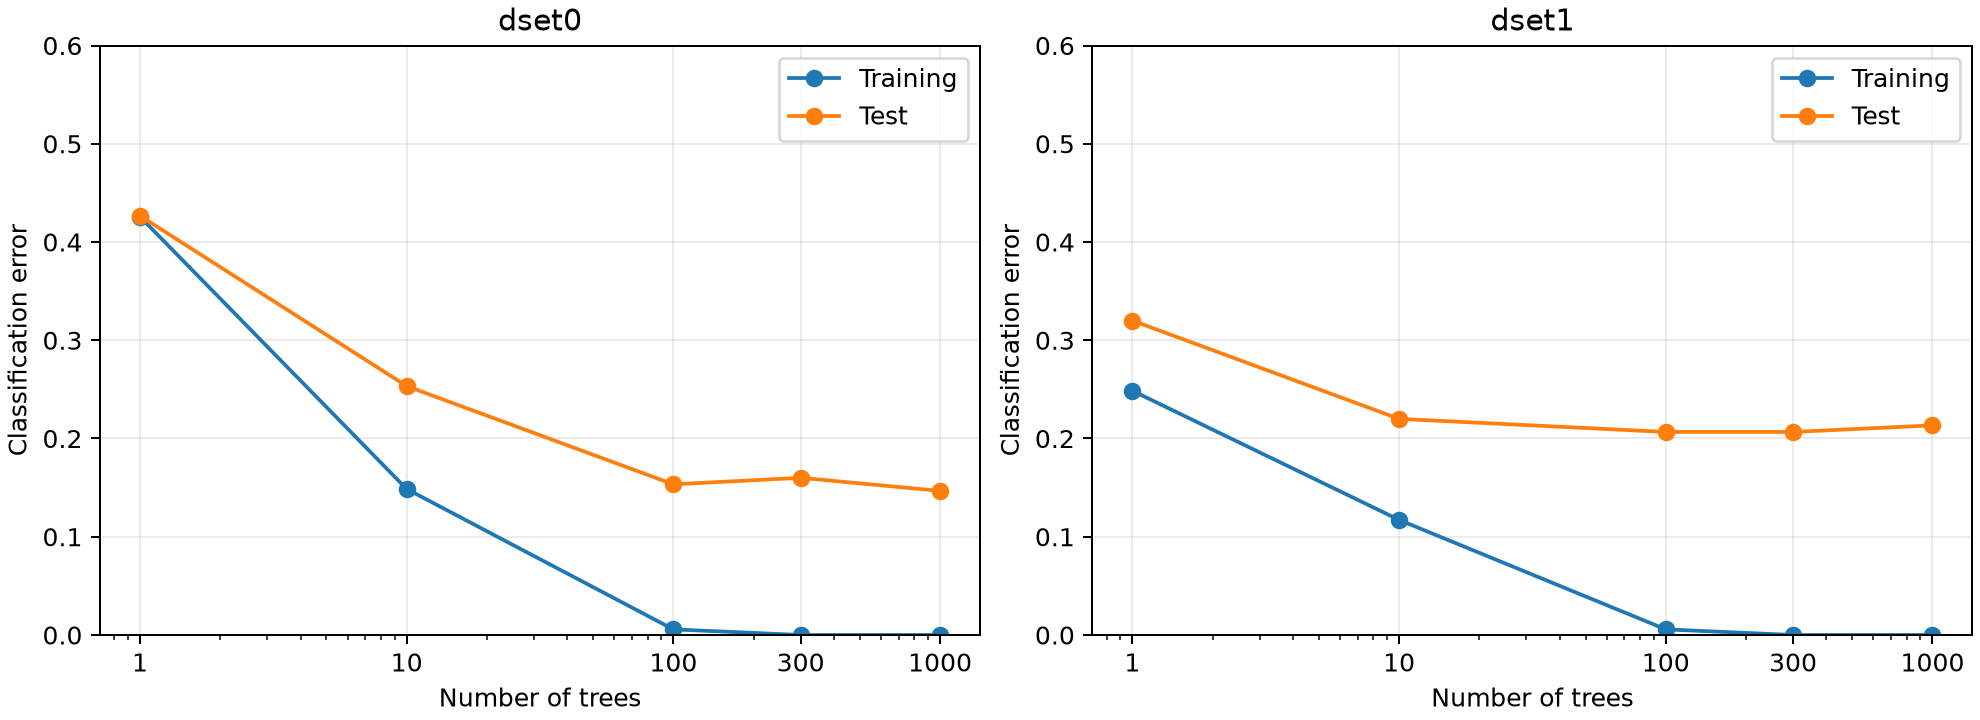

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)
for ax, name, results in zip(axes, ["dset0", "dset1"], [results0, results1]):
    ax.plot(results["Trees"], results["Training error"], "o-", label="Training")
    ax.plot(results["Trees"], results["Test error"], "o-", label="Test")
    ax.set_xscale("log")
    ax.set_xticks(results["Trees"], [str(n) for n in results["Trees"]])
    ax.set_xlabel("Number of trees")
    ax.set_ylabel("Classification error")
    ax.set_title(name)
    ax.set_ylim(0, 0.6)
    ax.grid(alpha=0.25)
    ax.legend()
fig.savefig("classification_error.png", dpi=180)
plt.close(fig)


from IPython.display import Image, display
display(Image(filename="classification_error.png"))

### Plot log-loss

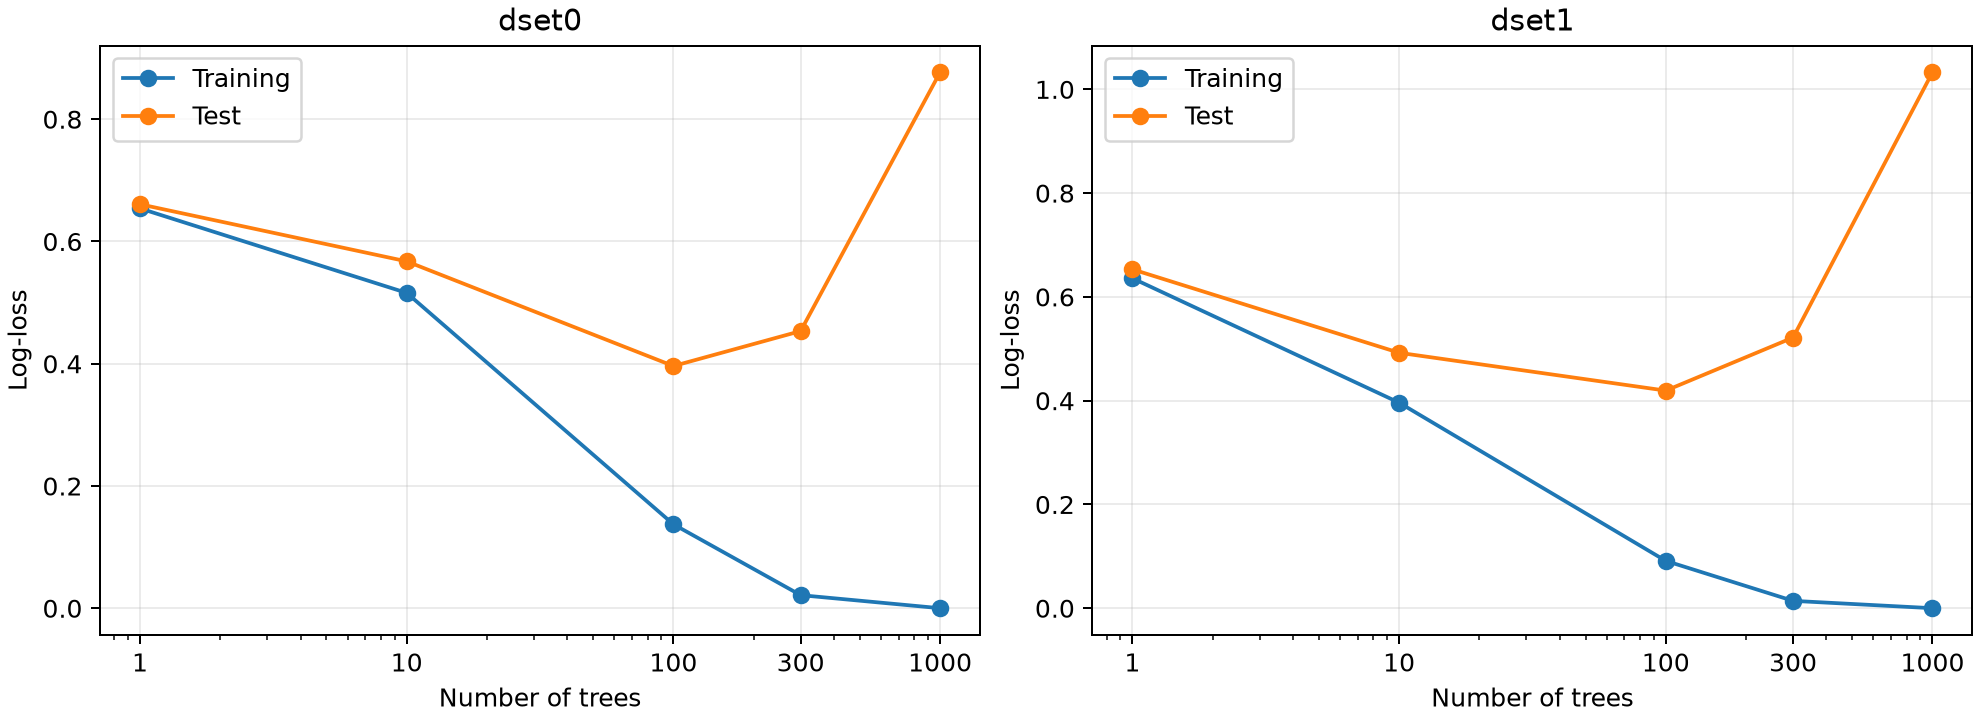

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)
for ax, name, results in zip(axes, ["dset0", "dset1"], [results0, results1]):
    ax.plot(results["Trees"], results["Training log-loss"], "o-", label="Training")
    ax.plot(results["Trees"], results["Test log-loss"], "o-", label="Test")
    ax.set_xscale("log")
    ax.set_xticks(results["Trees"], [str(n) for n in results["Trees"]])
    ax.set_xlabel("Number of trees")
    ax.set_ylabel("Log-loss")
    ax.set_title(name)
    ax.grid(alpha=0.25)
    ax.legend()
fig.savefig("log_loss.png", dpi=180)
plt.close(fig)

from IPython.display import Image, display
display(Image(filename="log_loss.png"))

## (a) Results for dset0

| Trees | Training error | Test error | Training log-loss | Test log-loss |
|---:|---:|---:|---:|---:|
| 1 | 0.425714 | 0.426667 | 0.654093 | 0.660869 |
| 10 | 0.148571 | 0.253333 | 0.515841 | 0.567680 |
| 100 | 0.005714 | 0.153333 | 0.137334 | 0.396942 |
| 300 | 0.000000 | 0.166667 | 0.021441 | 0.455769 |
| 1000 | 0.000000 | 0.146667 | 0.000098 | 0.880485 |

Training classification error decreases from 0.425714 to zero. Test error generally improves as more trees are added: it falls from 0.426667 with one tree to 0.153333 with 100 trees. At 300 and 1000 trees, it is 0.166667 and 0.146667, respectively.

Thus, increasing the number of trees does not cause a large deterioration in test classification error on this split. Most of the improvement occurs by 100 trees, with relatively small changes afterward.

However, test log-loss is lowest at 100 trees and then increases to 0.880485 at 1000 trees. This suggests that additional boosting can worsen probability predictions even when classification error remains similar.


## (b) Results for dset1

| Trees | Training error | Test error | Training log-loss | Test log-loss |
|---:|---:|---:|---:|---:|
| 1 | 0.248571 | 0.320000 | 0.635915 | 0.653116 |
| 10 | 0.117143 | 0.220000 | 0.396146 | 0.492309 |
| 100 | 0.005714 | 0.206667 | 0.091226 | 0.419280 |
| 300 | 0.000000 | 0.200000 | 0.014195 | 0.523208 |
| 1000 | 0.000000 | 0.213333 | 0.000047 | 1.035020 |

Training classification error also decreases to zero. Test error improves from 0.320000 with one tree to 0.220000 with 10 trees. It then changes relatively little: 0.206667 at 100 trees, 0.200000 at 300 trees, and 0.213333 at 1000 trees.

On this split, test classification error mostly levels off, with slight worsening at 1000 trees compared with 300. Test log-loss increases more clearly after 100 trees, reaching 1.035020 at 1000 trees, while training log-loss continues toward zero. This is evidence of overfitting in the probability predictions.


## (c) Explaining the generalization behavior

A possible explanation is a difference in **label noise or class overlap**. If the features contain a clearer signal and labels are more predictable, further boosting can improve classification after training error becomes very small. If labels are noisy or the classes overlap, later trees can fit details of the training sample that do not help on new observations.

The results are consistent with dset1 having more noise or overlap, or a pattern that is harder for the chosen trees to learn. However, the learning curves do not identify the true data-generating mechanism. With only 150 test observations, a change of 0.006667 represents one observation, so the small late-stage differences should not be overinterpreted.

Both datasets also show that classification error and log-loss can behave differently. Classification depends only on which side of 0.5 a probability falls. Log-loss also penalizes confidence in incorrect predictions. Continued boosting may therefore worsen log-loss without substantially changing the number of classification errors.
